[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/steeve-g/notebooks/20_retina_v2_cells_and_fisher.ipynb)

# Retina v2: Fisher information per cell, every W3 and tOFFalpha cell, and the stimulus features

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Tasks 1 and 2 for the retina (notebooks 12 and 13) on 10 test images, in three figures:
    1. **Tasks 1 and 2 with the Fisher information per cell**: the stimulus features $M_t^{\rm env}(x)$, and for W3 cell 176-exp7 and tOFFalpha cell 17-exp5 the leading eigenvectors of G(x) at a single noise scale, $M_t(x)$, with the Fisher information of each cell of the mosaic and its total per pixel, diag J(x), as in notebook 11.
    2. **Every cell of each type**: the same rows for the 5 W3 cells (and a second training run of cell 176-exp7) and for the 5 tOFFalpha cells, one figure per cell type and image, to judge by eye whether cells of one type give the same features.
    3. **The stimulus features with more samples**: 600 probes per noise scale instead of 150.

* **Requirements**: TinyImageNet, the retina checkpoints in `runs/` (the 11 models, staged from Baptiste's), a GPU, `multigeom` from the `g-per-scale` branch and `openretina` from the private repository `open-retina-multigeom`.

* **Time**: about 3.5 h on a GPU (the results are stored, and later runs reload them).

## 1. Setup

### 1.1. Install package

Install the version of `multigeom` this notebook needs, the `g-per-scale` branch on GitHub, and, on Google Colab, `openretina` from the private repository `open-retina-multigeom` (with a GitHub token stored in Colab's secrets as `GH_TOKEN`). Elsewhere, `multigeom` is installed only if the installed one lacks its functions, and `openretina` as the README of `tests/fixtures/retina/` says.

In [1]:
%%time

# the multigeom this notebook needs: the g-per-scale branch on GitHub, until it is
# released (without its dependencies: Colab already has torch, numpy, scipy and
# matplotlib, and reinstalling torch is slow and can break the GPU runtime)
import os
import sys

BRANCH = "git+https://github.com/multigeom/multigeom.git@g-per-scale"

# on Google Colab: install the latest commit of that branch (forced: pip skips a
# branch it installed before, even if the branch has changed since), and the
# diffusion models' library
if "google.colab" in sys.modules:
    %pip install -q --no-deps --force-reinstall {BRANCH}
    %pip install -q "diffusers>=0.30,<0.38"

    # an older multigeom imported earlier in this session stays in memory: restart
    # the session so that the next cells import the new one (then run them from the
    # next cell on)
    # open-retina with Baptiste Lorenzi's retina models: the private repository
    # open-retina-multigeom, with a GitHub token in Colab's secrets (GH_TOKEN)
    from google.colab import userdata

    TOKEN = userdata.get("GH_TOKEN")
    RETINA = "github.com/steevelaquitaine/open-retina-multigeom.git"
    %pip install -q --no-deps "git+https://{TOKEN}@{RETINA}"
    DEPENDENCIES = (
        "jaxtyping hydra-core lightning tenacity opencv-python-headless seaborn"
    )
    %pip install -q {DEPENDENCIES} moviepy

    if "multigeom" in sys.modules:
        print("restarting the session to load the new multigeom: run the next cells")
        os.kill(os.getpid(), 9)

# on your own machine: install that branch only if the installed multigeom lacks its
# functions (this replaces an editable install; restart the kernel afterwards)
else:
    import multigeom

    if not hasattr(multigeom.analysis, "compute_bootstrap"):
        %pip install -q --no-deps {BRANCH}
        print("installed multigeom from the g-per-scale branch: restart the kernel")

CPU times: user 3.07 s, sys: 94 ms, total: 3.16 s
Wall time: 591 ms


### 1.2. Imports and parameters

Work from the repository root, import the packages, and set the parameters: the cells and their models, the test images, the samples per noise scale, and where the results and figures go.

<details><summary>Details</summary>

* `load_retina` loads a cell's models with the Poisson noise of its responses (notebook 12); `compute_per_scale` gives $M_t(x)$ at each noise scale, `compute_env` the stimulus features (notebook 13), and `compute_fisher_per_cell` the Fisher information of each cell of the mosaic, with the Poisson noise of its responses: $J_n(x) = g_n g_n^\top$ with $g_n = \sqrt{g/\lambda_n}\, \nabla \lambda_n(x)$, $\lambda_n$ the rate of cell $n$ and $g$ the exposure.
* The mosaic of a cell is that cell's model slid over a hexagonal lattice: its "cells" are copies of one recorded cell at different positions.

</details>

In [2]:
%%time

import copy
import os
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from huggingface_hub import snapshot_download

# move to the repository root (the folder containing environment.yml): data/, runs/
# and assets/ are read and written from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

print("repo root:", root)

from multigeom.config import load_config
from multigeom.datasets import download_tinyimagenet
from multigeom.encoders.retina import load_retina, load_retina_test_images
from multigeom.geometry import compute_fisher_per_cell
from multigeom.pipeline.per_scale import compute_env, compute_per_scale
from multigeom.plotting import plot_per_scale
from multigeom.utils import get_device, load_intermediate, save_intermediate

# the parameters of this notebook
PARAMS = {
    # the cells of each type (runs/<stage>/lorenzi/<area>/): the first of each type is
    # its reference cell (that of notebooks 12 to 15), and W3 176-exp7 also has a
    # second training run of its diffusion model (seed 1)
    "cells": {
        "W3": {
            "176-exp7": "retina-W3_176-exp7",
            "176-exp7 seed 1": "retina-W3_176-exp7-seed1",
            "1952-exp6": "retina-W3_1952-exp6",
            "686-exp4": "retina-W3_686-exp4",
            "903-exp7": "retina-W3_903-exp7",
            "915-exp4": "retina-W3_915-exp4",
        },
        "tOFFalpha": {
            "17-exp5": "retina-tOFFalpha_17-exp5",
            "1018-exp4": "retina-tOFFalpha_1018-exp4",
            "170-exp7": "retina-tOFFalpha_170-exp7",
            "412-exp5": "retina-tOFFalpha_412-exp5",
            "418-exp5": "retina-tOFFalpha_418-exp5",
        },
    },
    # the test images: TinyImageNet training images 50,000 to 50,009 in open-retina's
    # shuffled order (the first 6 are close to those of notebooks 12 to 15, which were
    # standardised as a group of 6)
    "n_images": 10,
    "frames": "data/tiny-imagenet-200/train",
    "normalizer": "data/02_intermediate/retina/normalizer.pt",
    # Monte-Carlo samples per noise scale: pairs of responses for M_t(x) (150, as in
    # notebook 12), probes for the stimulus features (600, 4 times notebook 13's)
    "n_samples": 150,
    "n_env_samples": 600,
    # probes per batch of the stimulus features (10 fit in the GPU's memory at
    # 120 x 120), the noisy images per probe, the finite-difference step in units of
    # √t, and the shift of their seeds (notebook 13)
    "batch_size": 10,
    "n_noisy": 8,
    "eta": 0.02,
    "env_seed_offset": 100_000,
    # leading eigenvectors kept and drawn at each noise scale, and the cells of the
    # mosaic whose Fisher information is kept (the strongest) for the figures
    "n_eigvecs": 4,
    "n_fisher_cells": 24,
    # in the figures: each cell's Fisher pattern drawn as the 32 x 32 pixels around
    # its peak (a cell of the mosaic is much smaller than the image), and the title
    # of the Fisher rows
    "fisher_crop": 32,
    "fisher_title": "J(x) per cells of the mosaic",
    "fisher_label_without_name": True,
    # the cell type whose diffusion model gives the stimulus statistics (its null
    # token, as in notebook 13)
    "prior_cell_type": "W3",
    # where the results are stored (True: recompute and overwrite them), where the
    # figures are saved, their resolution in the file and on screen, and the images
    # whose figures stay in the notebook
    "intermediate_dir": "data/02_intermediate/20_retina_v2",
    "recompute": False,
    "figure_dir": "assets/figures/retina/v2",
    "file_dpi": 200,
    "screen_dpi": 100,
    "show": ["img2"],
}

# the estimator config (packaged with multigeom)
est_cfg = load_config("estimator")

# compute device
device = get_device(None)
print("device:", device)

repo root: /home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials


device: cuda
CPU times: user 678 ms, sys: 113 ms, total: 790 ms
Wall time: 815 ms


## 2. Download the retina models and the datasets

The checkpoints of the reference cells are on Hugging Face; those of the other cells are staged in `runs/` from Baptiste's (`from_baptiste/Pretrained_retina_diffusion/weights/` and the encoder checkpoints in `datasets/proj_multigeom/open-retina-multigeom/`). TinyImageNet gives the test images.

In [3]:
%%time

# the retina checkpoints on Hugging Face (files already in runs/ are kept), and
# TinyImageNet (nothing if already there)
snapshot_download(
    repo_id="steevelaquitaine/multigeom", local_dir="runs", allow_patterns="*/lorenzi/*"
)
download_tinyimagenet()

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

CPU times: user 27.6 ms, sys: 6.03 ms, total: 33.6 ms
Wall time: 419 ms


PosixPath('/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/data/tiny-imagenet-200')

## 3. $M_t(x)$ and the Fisher information per cell, for every cell

For each cell's mosaic and each test image: the leading eigenvectors of $M_t(x)$ at each noise scale (as in notebook 12), and the Fisher information of each cell of the mosaic (as in notebook 11, with Poisson noise). Each cell's results are stored in `data/02_intermediate/20_retina_v2/<area>.pt` as soon as they are computed, the reference cells first.

<details><summary>Details</summary>

* Only the strongest `n_fisher_cells` cells of the mosaic are kept (their patterns and Fisher information), with the total over all the cells, diag J(x), which the figures draw.
* The test images are the same for every cell: they are standardised with the image units of the diffusion models, which do not depend on the cell.

</details>

In [4]:
%%time

# 1. the estimator settings: those of notebook 12
cfg = copy.deepcopy(est_cfg)
cfg.monte_carlo.n_samples = PARAMS["n_samples"]
cfg.top_k = PARAMS["n_eigvecs"]
frames = Path(PARAMS["frames"])
intermediate_dir = Path(PARAMS["intermediate_dir"])


def get_strongest(fisher: dict, n_cells: int) -> dict:
    """The Fisher information of the `n_cells` strongest cells, with the total over
    all the cells per pixel, diag J(x) ("diag"), in float32."""
    order = fisher["cell_values"].argsort()[::-1][:n_cells]
    return {
        "cells": fisher["cells"][order].astype("float32"),
        "cell_values": fisher["cell_values"][order],
        "diag": (fisher["cells"] ** 2).sum(axis=0),
    }


# 2. every cell, reloaded if stored, else computed and stored; results[area] holds,
# per image, M_t(x) ("per_scale") and the Fisher information per cell ("fisher")
results, examples = {}, None
for cell_type, cells in PARAMS["cells"].items():
    for cell, area in cells.items():
        area_file = intermediate_dir / f"{area}.pt"
        if area_file.exists() and not PARAMS["recompute"]:
            results[area], examples = load_intermediate(area_file)
            continue

        # the cell's models, the test images and their seeds, and the Poisson noise
        models = load_retina(
            area, Path("runs"), frames, device, normalizer_cache=PARAMS["normalizer"]
        )
        cfg.monte_carlo.noise = models.noise
        images = load_retina_test_images(models, frames, n=PARAMS["n_images"])
        examples = {
            f"img{i}": (image[None], int(cfg.seed) + i)
            for i, image in enumerate(images)
        }

        # M_t(x), then the Fisher information per cell, of every image
        per_scale = compute_per_scale(
            examples, models.encoder, models.unet, models.alphas_cumprod, cfg, device
        )
        fisher = {
            name: get_strongest(
                compute_fisher_per_cell(
                    image, models.encoder, 1.0, device, noise=models.noise
                ),
                PARAMS["n_fisher_cells"],
            )
            for name, (image, _) in examples.items()
        }
        results[area] = {"per_scale": per_scale, "fisher": fisher}
        save_intermediate((results[area], examples), area_file)
        print(cell_type, cell, "done")
        del models
        torch.cuda.empty_cache()

CPU times: user 114 ms, sys: 280 ms, total: 394 ms
Wall time: 394 ms


## 4. The stimulus features, with 600 probes per noise scale

As in notebook 13, from the null token of the W3 reference model, with 4 times more probes, stored per image in `data/02_intermediate/20_retina_v2/stimulus_features/`.

In [5]:
%%time

# the settings: 4 times more probes than notebook 13
env_cfg = copy.deepcopy(cfg)
env_cfg.monte_carlo.n_samples = PARAMS["n_env_samples"]
env_cfg.monte_carlo.batch_size = PARAMS["batch_size"]
env_dir = intermediate_dir / "stimulus_features"

# one image at a time, each reloaded if stored, else computed and stored (about
# 12 min per image)
env, models = {}, None
for name, example in examples.items():
    image_file = env_dir / f"{name}.pt"
    if image_file.exists() and not PARAMS["recompute"]:
        env[name] = load_intermediate(image_file)
        continue
    if models is None:
        area = next(iter(PARAMS["cells"][PARAMS["prior_cell_type"]].values()))
        models = load_retina(
            area, Path("runs"), frames, device, normalizer_cache=PARAMS["normalizer"]
        )
    env[name] = compute_env(
        {name: example}, models.unet, models.alphas_cumprod, env_cfg, device, PARAMS
    )[name]
    save_intermediate(env[name], image_file)
    print(name, "done")
print("stimulus features done:", len(env), "images")

stimulus features done: 10 images
CPU times: user 2.43 ms, sys: 12.9 ms, total: 15.4 ms
Wall time: 15.3 ms


## 5. Figure 1: tasks 1 and 2 with the Fisher information per cell

One figure per image, saved to `assets/figures/retina/v2/figure1/`: the image (A); the stimulus features (B); for the W3 and tOFFalpha reference cells, the leading eigenvectors of $M_t(x)$ at each noise scale, then the Fisher information of the 24 strongest cells of the mosaic ("per cell") and its total per pixel ("diag J(x)"); and the eigenvalues. The Fisher rows do not depend on the noise scale: their columns are cells, strongest first.

CPU times: user 26.7 s, sys: 655 ms, total: 27.3 s
Wall time: 25.1 s


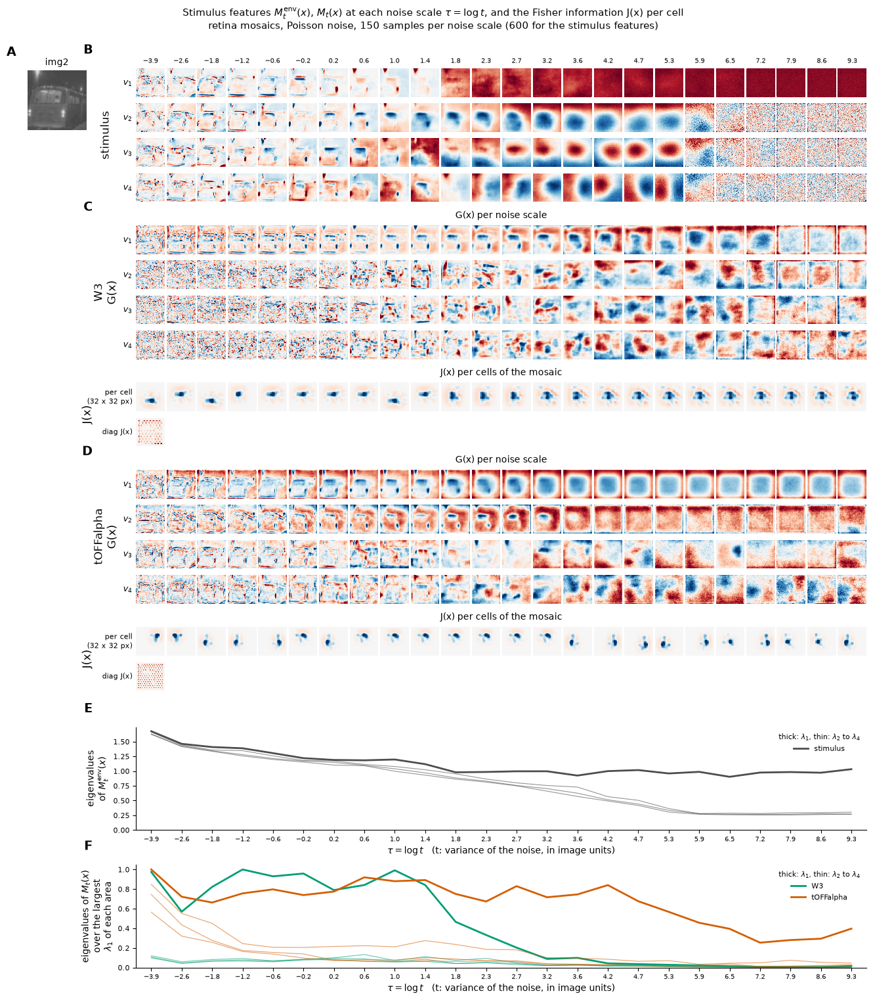

In [6]:
%%time

# 1. the folders of the figures, and the references of each cell type
figure_dir = Path(PARAMS["figure_dir"])
references = {
    cell_type: next(iter(cells.values()))
    for cell_type, cells in PARAMS["cells"].items()
}


def save(fig: plt.Figure, folder: str, name: str, keep: bool) -> None:
    """Save `fig` as `folder`/`name`.png in the figure folder, and close it unless
    `keep`."""
    (figure_dir / folder).mkdir(parents=True, exist_ok=True)
    fig.savefig(
        figure_dir / folder / f"{name}.png", dpi=PARAMS["file_dpi"], bbox_inches="tight"
    )
    if not keep:
        plt.close(fig)


# 2. one figure per image
suptitle = (
    r"Stimulus features $M_t^{\rm env}(x)$, $M_t(x)$ at each noise scale"
    r" $\tau = \log t$, and the Fisher information J(x) per cell"
    f"\nretina mosaics, Poisson noise, {PARAMS['n_samples']} samples per noise scale"
    f" ({PARAMS['n_env_samples']} for the stimulus features)"
)
for name, (image, _) in examples.items():
    records = {"stimulus": env[name]}
    records.update({t: results[a]["per_scale"][name] for t, a in references.items()})
    fisher = {t: results[a]["fisher"][name] for t, a in references.items()}
    fig, _ = plot_per_scale(image.cpu(), records, PARAMS, name, suptitle, {}, fisher)
    save(fig, "figure1", f"stimulus_features_and_fisher_{name}", name in PARAMS["show"])

## 6. Figure 2: every cell of each type

One figure per cell type and image, saved to `assets/figures/retina/v2/figure2_<cell type>/`: for each cell, the leading eigenvectors of $M_t(x)$ at each noise scale and its Fisher rows, the reference cell first. If the cells of one type encode the same features, their rows look alike; the two training runs of W3 176-exp7 show how much differs from training alone.

CPU times: user 1min 34s, sys: 1.54 s, total: 1min 36s
Wall time: 1min 31s


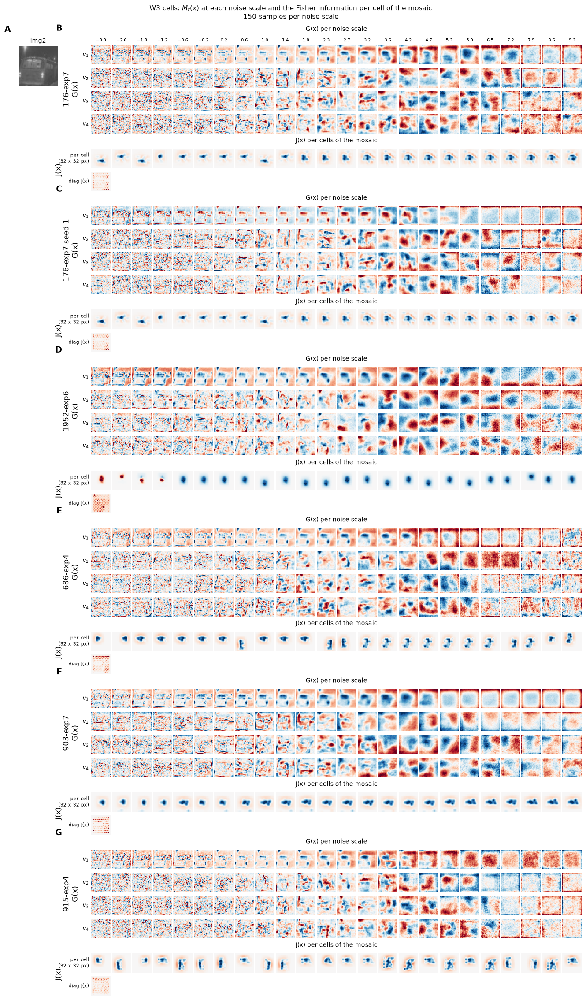

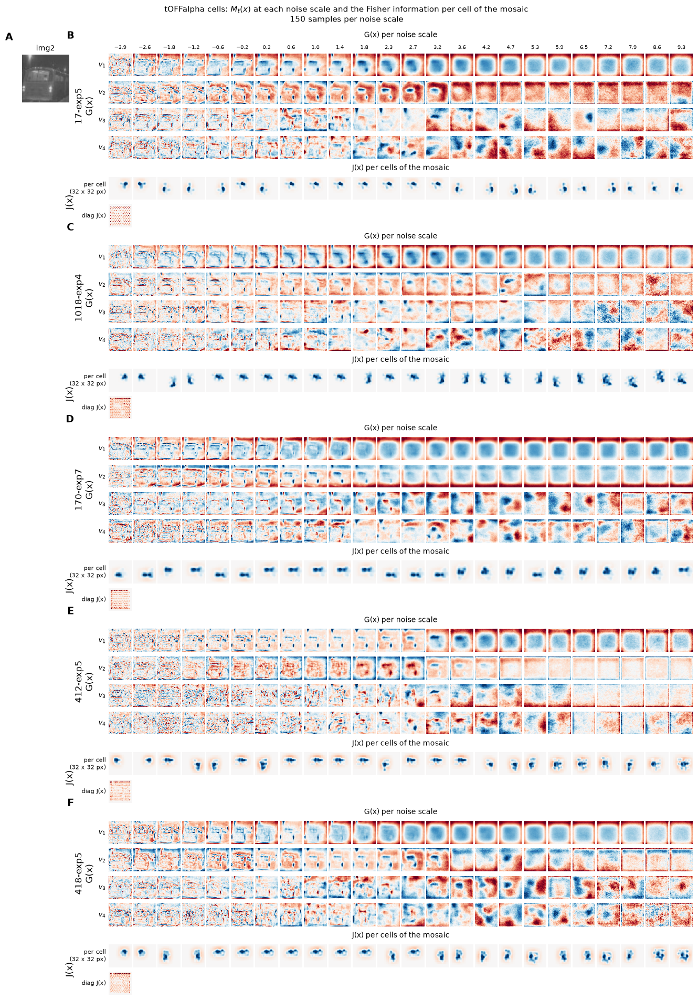

In [7]:
%%time

for cell_type, cells in PARAMS["cells"].items():
    title = (
        f"{cell_type} cells: $M_t(x)$ at each noise scale and the Fisher information"
        f" per cell of the mosaic\n{PARAMS['n_samples']} samples per noise scale"
    )
    for name, (image, _) in examples.items():
        records = {
            cell: results[area]["per_scale"][name] for cell, area in cells.items()
        }
        fisher = {cell: results[area]["fisher"][name] for cell, area in cells.items()}
        fig, _ = plot_per_scale(
            image.cpu(), records, PARAMS, name, title, {}, fisher, eigenvalues=False
        )
        keep = name in PARAMS["show"]
        save(fig, f"figure2_{cell_type}", f"cells_{cell_type}_{name}", keep)

## 7. Figure 3: the stimulus features with 600 probes per noise scale

One figure per image, saved to `assets/figures/retina/v2/figure3/`: the stimulus features alone, with their eigenvalues, to compare with those of notebook 13 (150 probes).

CPU times: user 8.71 s, sys: 150 ms, total: 8.86 s
Wall time: 7.15 s


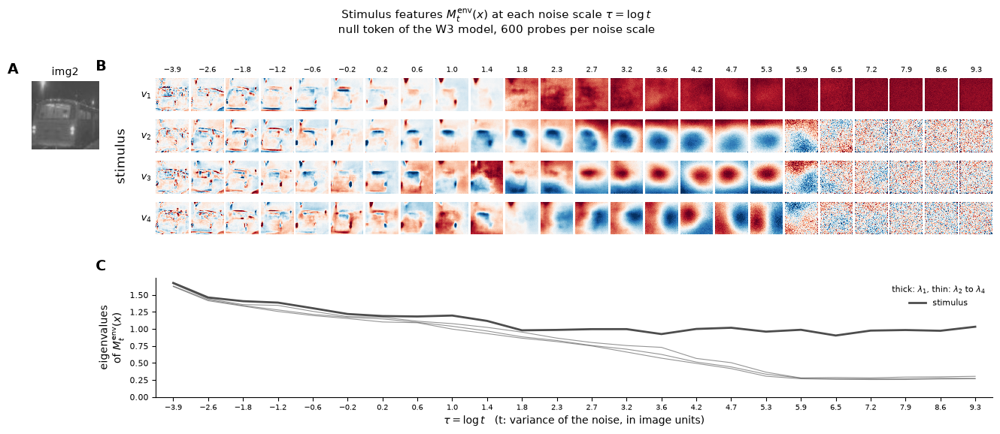

In [8]:
%%time

title = (
    r"Stimulus features $M_t^{\rm env}(x)$ at each noise scale $\tau = \log t$"
    f"\nnull token of the W3 model, {PARAMS['n_env_samples']} probes per noise scale"
)
for name, (image, _) in examples.items():
    records = {"stimulus": env[name]}
    fig, _ = plot_per_scale(image.cpu(), records, PARAMS, name, title, {})
    save(fig, "figure3", f"stimulus_features_{name}", name in PARAMS["show"])

## 8. Conclusion

(written after the run)